<a href="https://colab.research.google.com/github/velezverespeter/energy-trading-risk/blob/main/notebooks/02_market_risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

daily = pd.read_csv("si_prices_daily.csv", index_col=0, parse_dates=True)
daily.head()

,base,peak
date,,
2021-01-01,46.405217,49.247500
2021-01-02,33.857917,NaN
2021-01-03,40.925000,NaN
2021-01-04,50.570000,61.125000
2021-01-05,57.294583,66.015833


In [4]:
daily["change"] = daily["base"].diff()
daily["change"].describe()

,change
count,1826.000000
mean,0.025780
std,33.209618
min,-161.223333
25%,-15.275833
50%,-2.030833
75%,10.965000
max,251.240000


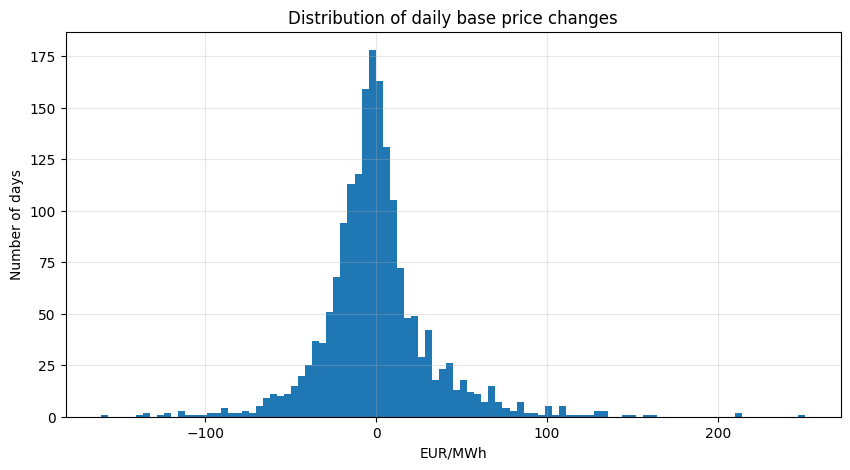

In [5]:
daily["change"].hist(bins=100, figsize=(10, 5))
plt.title("Distribution of daily base price changes")
plt.xlabel("EUR/MWh")
plt.ylabel("Number of days")
plt.grid(alpha=0.3)
plt.show()

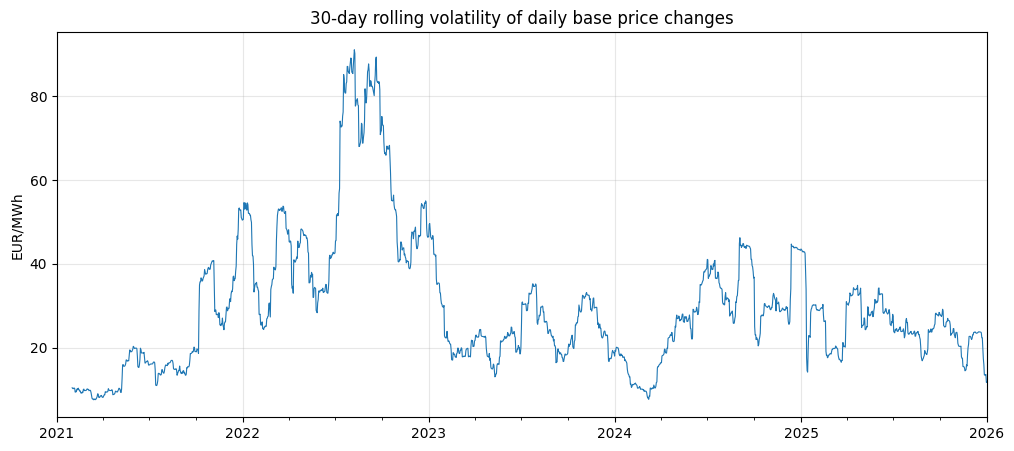

In [6]:
daily["volatility"] = daily["change"].rolling(30).std()

daily["volatility"].plot(figsize=(12, 5), linewidth=0.8)
plt.title("30-day rolling volatility of daily base price changes")
plt.ylabel("EUR/MWh")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.show()

In [7]:
daily.tail(3)

,base,peak,change,volatility
date,,,,
2025-12-30,90.52000,95.630000,-10.931667,13.601540
2025-12-31,95.42625,102.776667,4.906250,11.715538
2026-01-01,93.48000,NaN,-1.946250,11.715547


In [8]:
daily = daily[daily.index < "2026-01-01"]
daily.tail(3)

,base,peak,change,volatility
date,,,,
2025-12-29,101.451667,109.104167,7.536667,13.498812
2025-12-30,90.520000,95.630000,-10.931667,13.601540
2025-12-31,95.426250,102.776667,4.906250,11.715538


In [9]:
pozicija_mwh = 10 * 24

daily["pnl"] = pozicija_mwh * daily["change"]

var_95 = -daily["pnl"].quantile(0.05)
var_99 = -daily["pnl"].quantile(0.01)

print(f"Dnevni VaR 95 %: {var_95:,.0f} EUR")
print(f"Dnevni VaR 99 %: {var_99:,.0f} EUR")

Dnevni VaR 95 %: 10,881 EUR
Dnevni VaR 99 %: 21,322 EUR


In [10]:
var_po_letih = -daily["pnl"].groupby(daily.index.year).quantile(0.05)
var_po_letih.round(0)

,pnl
date,
2021,7787.0
2022,20036.0
2023,8780.0
2024,9195.0
2025,7904.0


In [11]:
std = daily["pnl"].std()

print(f"Normalni VaR 95 %:    {1.645 * std:,.0f} EUR")
print(f"Zgodovinski VaR 95 %: {var_95:,.0f} EUR")
print()
print(f"Normalni VaR 99 %:    {2.326 * std:,.0f} EUR")
print(f"Zgodovinski VaR 99 %: {var_99:,.0f} EUR")

Normalni VaR 95 %:    13,115 EUR
Zgodovinski VaR 95 %: 10,881 EUR

Normalni VaR 99 %:    18,544 EUR
Zgodovinski VaR 99 %: 21,322 EUR


In [12]:
okno = 250  # približno eno leto trgovalnih dni

daily["var_95"] = -daily["pnl"].rolling(okno).quantile(0.05).shift(1)
daily["preseganje"] = daily["pnl"] < -daily["var_95"]

test = daily.dropna(subset=["var_95"])
st_preseganj = test["preseganje"].sum()
st_dni = len(test)

print(f"Število dni v testu: {st_dni}")
print(f"Število preseganj:   {st_preseganj}")
print(f"Delež preseganj:     {st_preseganj / st_dni:.1%} (pričakovano 5 %)")

Število dni v testu: 1575
Število preseganj:   101
Delež preseganj:     6.4% (pričakovano 5 %)


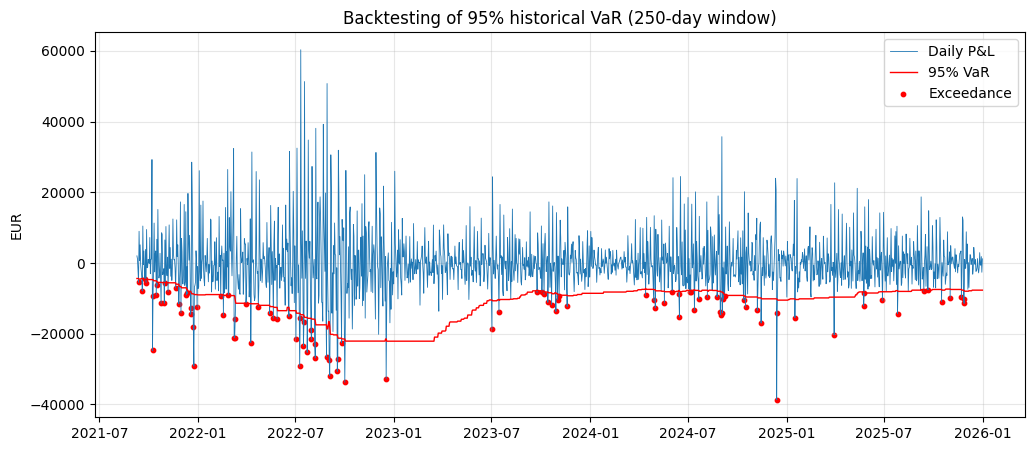

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(test.index, test["pnl"], linewidth=0.6, label="Daily P&L")
plt.plot(test.index, -test["var_95"], color="red", linewidth=1, label="95% VaR")
plt.scatter(test.index[test["preseganje"]], test["pnl"][test["preseganje"]],
            color="red", s=10, label="Exceedance")
plt.title("Backtesting of 95% historical VaR (250-day window)")
plt.ylabel("EUR")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

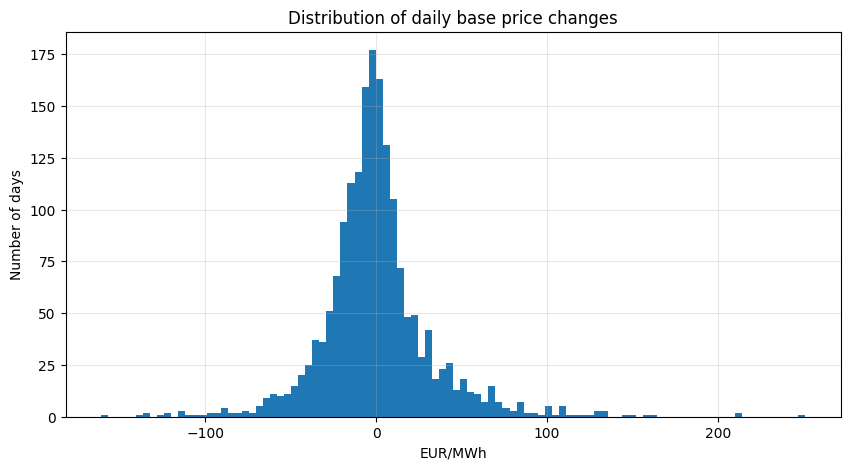

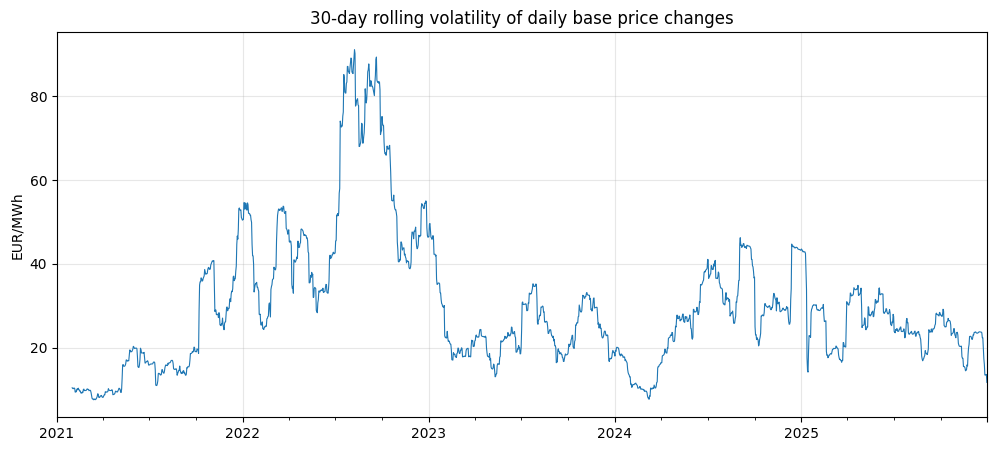

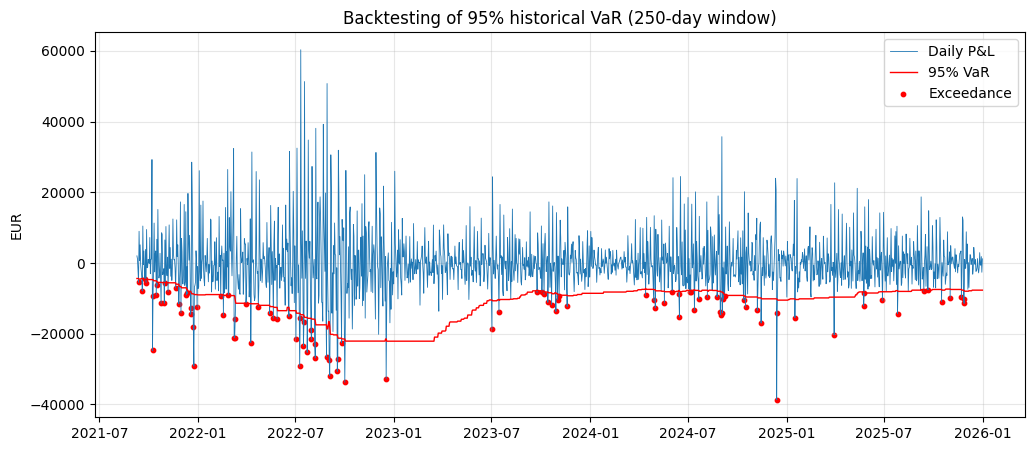

In [14]:
# Graf 1: histogram sprememb cen
daily["change"].hist(bins=100, figsize=(10, 5))
plt.title("Distribution of daily base price changes")
plt.xlabel("EUR/MWh")
plt.ylabel("Number of days")
plt.grid(alpha=0.3)
plt.savefig("change_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Graf 2: nestanovitnost
daily["volatility"].plot(figsize=(12, 5), linewidth=0.8)
plt.title("30-day rolling volatility of daily base price changes")
plt.ylabel("EUR/MWh")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.savefig("volatility.png", dpi=150, bbox_inches="tight")
plt.show()

# Graf 3: backtesting VaR
plt.figure(figsize=(12, 5))
plt.plot(test.index, test["pnl"], linewidth=0.6, label="Daily P&L")
plt.plot(test.index, -test["var_95"], color="red", linewidth=1, label="95% VaR")
plt.scatter(test.index[test["preseganje"]], test["pnl"][test["preseganje"]],
            color="red", s=10, label="Exceedance")
plt.title("Backtesting of 95% historical VaR (250-day window)")
plt.ylabel("EUR")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("var_backtest.png", dpi=150, bbox_inches="tight")
plt.show()